# VisionGuard AI - Milestone 01: Dataset Exploration & Integrity Check

**Objective:**
1. Inspect and validate the MVTec AD dataset structure for the target categories: `metal_nut`, `screw`, and `capsule`.
2. Visualize normal training samples vs. various defect categories.
3. Inspect pixel-level ground truth masks to understand defect morphology.
4. Assess resolution, color space, and intensity distribution to inform our preprocessing pipeline.

In [10]:
import os
from pathlib import Path
import yaml
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# If running from inside the notebooks/ directory, move to the project root
if Path.cwd().name == "notebooks":
    os.chdir("..")

print(f"Working directory: {Path.cwd()}")

# Load configuration from our central data config
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

raw_data_dir = Path(config["dataset"]["raw_dir"])
target_categories = config["dataset"]["target_categories"]

print(f"Raw data directory: {raw_data_dir}")
print(f"Target categories:   {target_categories}")

Working directory: d:\Data Science\projects\VisionGuard-AI
Raw data directory: data\raw
Target categories:   ['metal_nut', 'screw', 'capsule']


## 1. Run Automated Integrity Verification

In [11]:
from src.data.verify_dataset import run_verification

# Run verification across metal_nut, screw, and capsule
is_valid = run_verification(str(raw_data_dir))

# Fail-fast assertion: Halt execution if data integrity is compromised
assert is_valid, "Dataset verification failed! Check missing directories or masks."


 VisionGuard AI - Dataset Verification
 Target Directory: D:\Data Science\projects\VisionGuard-AI\data\raw

Checking [metal_nut] ...
  [OK] Valid structure.
       Train (Normal): 220
       Test (Normal):  22
       Defect Types:   bent(25), color(22), flip(23), scratch(23)
Checking [screw] ...
  [OK] Valid structure.
       Train (Normal): 320
       Test (Normal):  41
       Defect Types:   manipulated_front(24), scratch_head(24), scratch_neck(25), thread_side(23), thread_top(23)
Checking [capsule] ...
  [OK] Valid structure.
       Train (Normal): 219
       Test (Normal):  23
       Defect Types:   crack(23), faulty_imprint(22), poke(21), scratch(23), squeeze(20)

--- Summary Table ---
 Category  Train (Normal)  Test (Normal)  Defect Images  Defect Classes Status
metal_nut             220             22             93               4  READY
    screw             320             41            119               5  READY
  capsule             219             23            109       

## 2. Inspect Image Dimensions and Properties

In [14]:
# Inspect dimensions and channels of raw training images and ground-truth masks
print("--- RAW IMAGE & MASK SPECIFICATIONS ---")
for cat in target_categories:
    sample_img_path = next((raw_data_dir / cat / "train" / "good").glob("*.png"))
    
    # Check original image using PIL
    with Image.open(sample_img_path) as img:
        img_size = img.size # (width, height)
        img_mode = img.mode
        
    # Check a defect test image and its corresponding mask
    sample_defect_dir = [d for d in (raw_data_dir / cat / "test").iterdir() if d.is_dir() and d.name != "good"][0]
    sample_defect_img_path = next(sample_defect_dir.glob("*.png"))
    sample_mask_path = raw_data_dir / cat / "ground_truth" / sample_defect_dir.name / f"{sample_defect_img_path.stem}_mask.png"
    
    with Image.open(sample_mask_path) as mask:
        mask_size = mask.size
        mask_mode = mask.mode
        
    # Load with OpenCV to check actual array data types and value ranges
    img_arr = cv2.imread(str(sample_img_path))
    mask_arr = cv2.imread(str(sample_mask_path), cv2.IMREAD_GRAYSCALE)
    
    print(f"\n[{cat.upper()}]")
    print(f"  Image File: {sample_img_path.name}")
    print(f"  Dimensions: {img_size[0]}x{img_size[1]} | Mode: {img_mode} | dtype: {img_arr.dtype} | Range: [{img_arr.min()}, {img_arr.max()}]")
    print(f"  Mask Dimensions: {mask_size[0]}x{mask_size[1]} | Mode: {mask_mode} | Unique Mask Values: {np.unique(mask_arr)}")

--- RAW IMAGE & MASK SPECIFICATIONS ---

[METAL_NUT]
  Image File: 000.png
  Dimensions: 700x700 | Mode: RGB | dtype: uint8 | Range: [13, 255]
  Mask Dimensions: 700x700 | Mode: L | Unique Mask Values: [  0 255]

[SCREW]
  Image File: 000.png
  Dimensions: 1024x1024 | Mode: L | dtype: uint8 | Range: [30, 210]
  Mask Dimensions: 1024x1024 | Mode: L | Unique Mask Values: [  0 255]

[CAPSULE]
  Image File: 000.png
  Dimensions: 1000x1000 | Mode: RGB | dtype: uint8 | Range: [11, 247]
  Mask Dimensions: 1000x1000 | Mode: L | Unique Mask Values: [  0 255]


## 3. Visualize Normal Samples vs Anomalous Samples with Ground-Truth Masks


==================== [METAL_NUT] DEFECT FOOTPRINT ====================
  • Defect: bent               | Defect Pixels:  23025 / 490000 (4.699%)
  • Defect: color              | Defect Pixels:   2135 / 490000 (0.436%)
  • Defect: flip               | Defect Pixels: 237351 / 490000 (48.439%)
  • Defect: scratch            | Defect Pixels:   9302 / 490000 (1.898%)


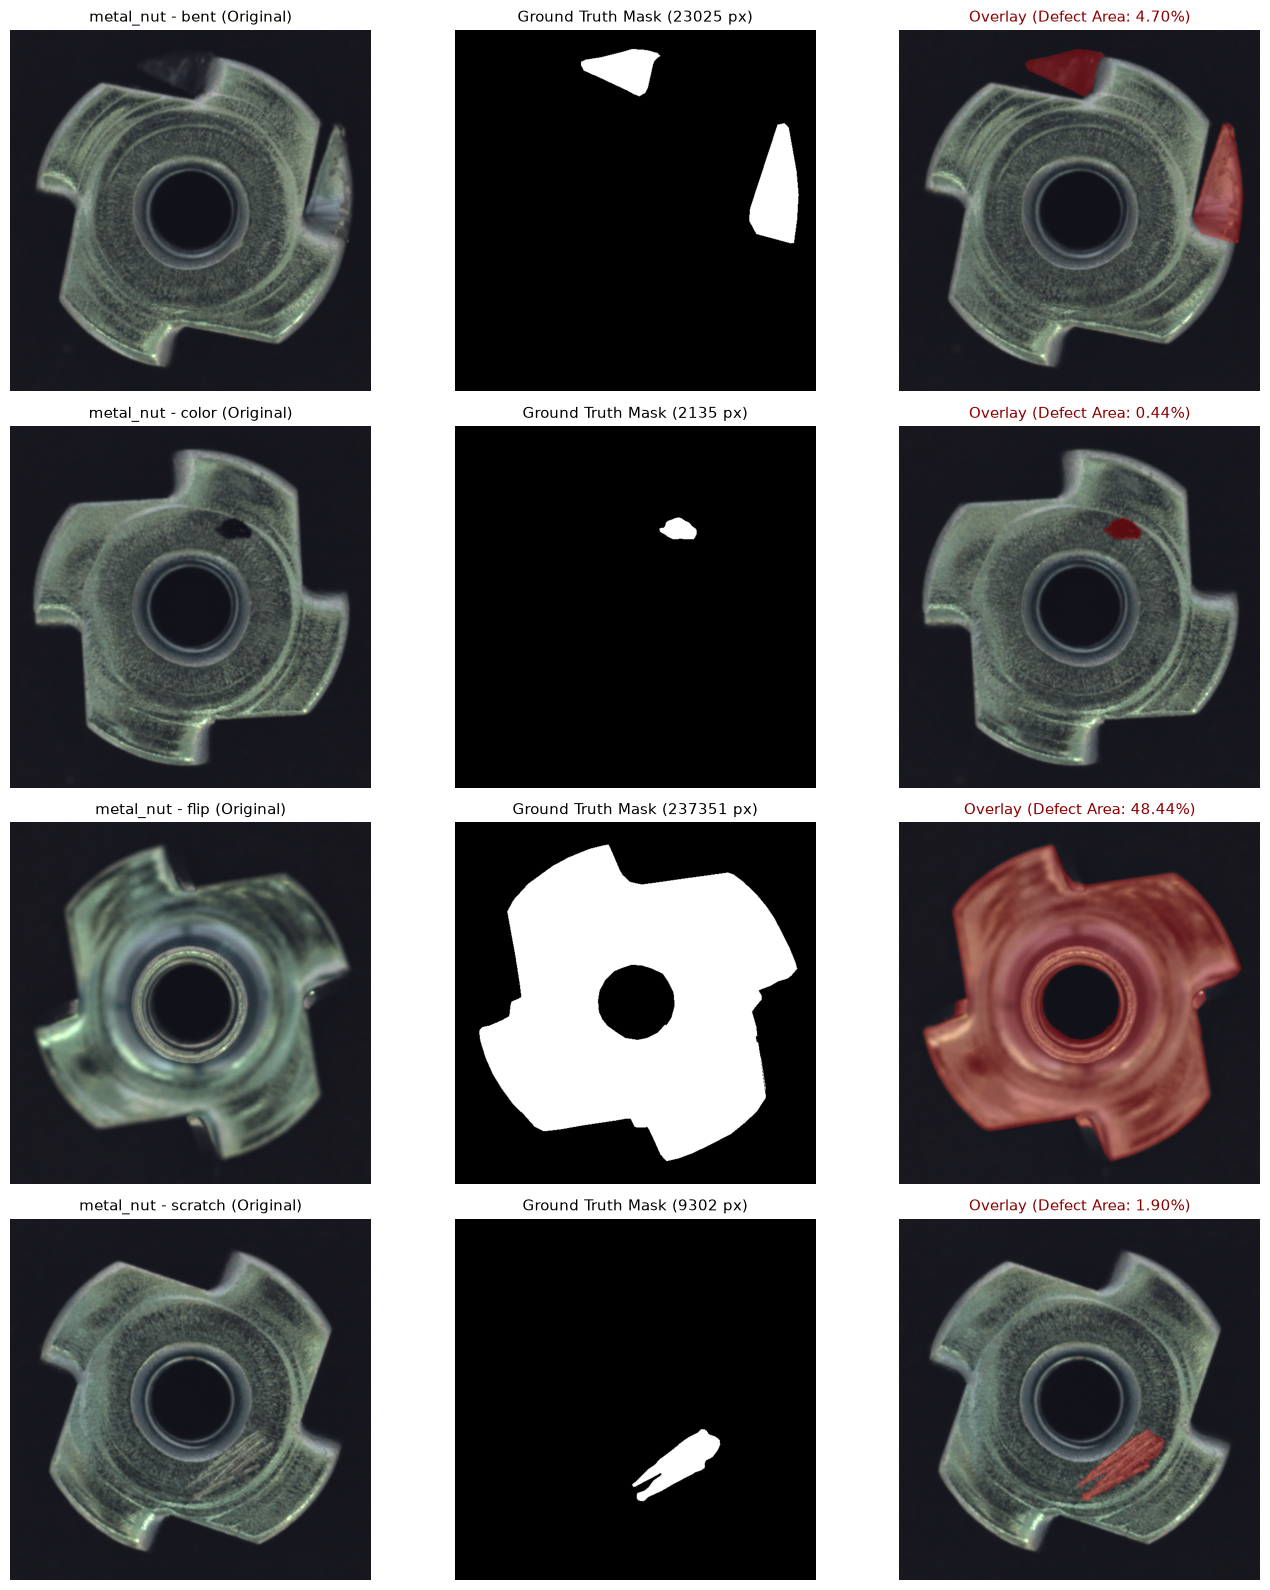

In [15]:
def visualize_category_defects(category: str, max_samples_per_defect: int = 1):
    """
    Visualizes defective test images, ground-truth masks, and highlighted overlays,
    while quantitatively computing the percentage of anomalous pixels.
    """
    test_dir = raw_data_dir / category / "test"
    gt_dir = raw_data_dir / category / "ground_truth"
    
    # Get all defect types excluding the 'good' test folder
    defect_types = sorted([d.name for d in test_dir.iterdir() if d.is_dir() and d.name != "good"])
    n_defects = len(defect_types)
    
    fig, axes = plt.subplots(n_defects, 3, figsize=(14, 4 * n_defects))
    if n_defects == 1:
        axes = np.expand_dims(axes, 0)
        
    print(f"\n==================== [{category.upper()}] DEFECT FOOTPRINT ====================")
    
    for i, defect in enumerate(defect_types):
        # Pick the first sample image for this defect type
        img_path = sorted(list((test_dir / defect).glob("*.png")))[0]
        mask_path = gt_dir / defect / f"{img_path.stem}_mask.png"
        
        # Load and convert BGR -> RGB
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Load ground truth binary mask
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        
        # Calculate anomalous area percentage
        total_pixels = mask.shape[0] * mask.shape[1]
        defect_pixels = np.count_nonzero(mask > 0)
        defect_percentage = (defect_pixels / total_pixels) * 100
        
        print(f"  • Defect: {defect:<18} | Defect Pixels: {defect_pixels:>6} / {total_pixels} ({defect_percentage:.3f}%)")
        
        # Create an overlay highlighting the defect in semi-transparent red
        overlay = img.copy()
        overlay[mask > 0] = [255, 0, 0] # Red mark on defect pixels
        blended = cv2.addWeighted(img, 0.7, overlay, 0.3, 0)
        
        # Column 1: Original Image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"{category} - {defect} (Original)", fontsize=11)
        axes[i, 0].axis("off")
        
        # Column 2: Ground Truth Mask
        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title(f"Ground Truth Mask ({defect_pixels} px)", fontsize=11)
        axes[i, 1].axis("off")
        
        # Column 3: Defect Overlay
        axes[i, 2].imshow(blended)
        axes[i, 2].set_title(f"Overlay (Defect Area: {defect_percentage:.2f}%)", fontsize=11, color="darkred")
        axes[i, 2].axis("off")
        
    plt.tight_layout()
    plt.show()

# Run visualization for metal_nut
visualize_category_defects("metal_nut")


==================== [SCREW] DEFECT FOOTPRINT ====================
  • Defect: manipulated_front  | Defect Pixels:   3806 / 1048576 (0.363%)
  • Defect: scratch_head       | Defect Pixels:   2767 / 1048576 (0.264%)
  • Defect: scratch_neck       | Defect Pixels:   2810 / 1048576 (0.268%)
  • Defect: thread_side        | Defect Pixels:   1580 / 1048576 (0.151%)
  • Defect: thread_top         | Defect Pixels:   6803 / 1048576 (0.649%)


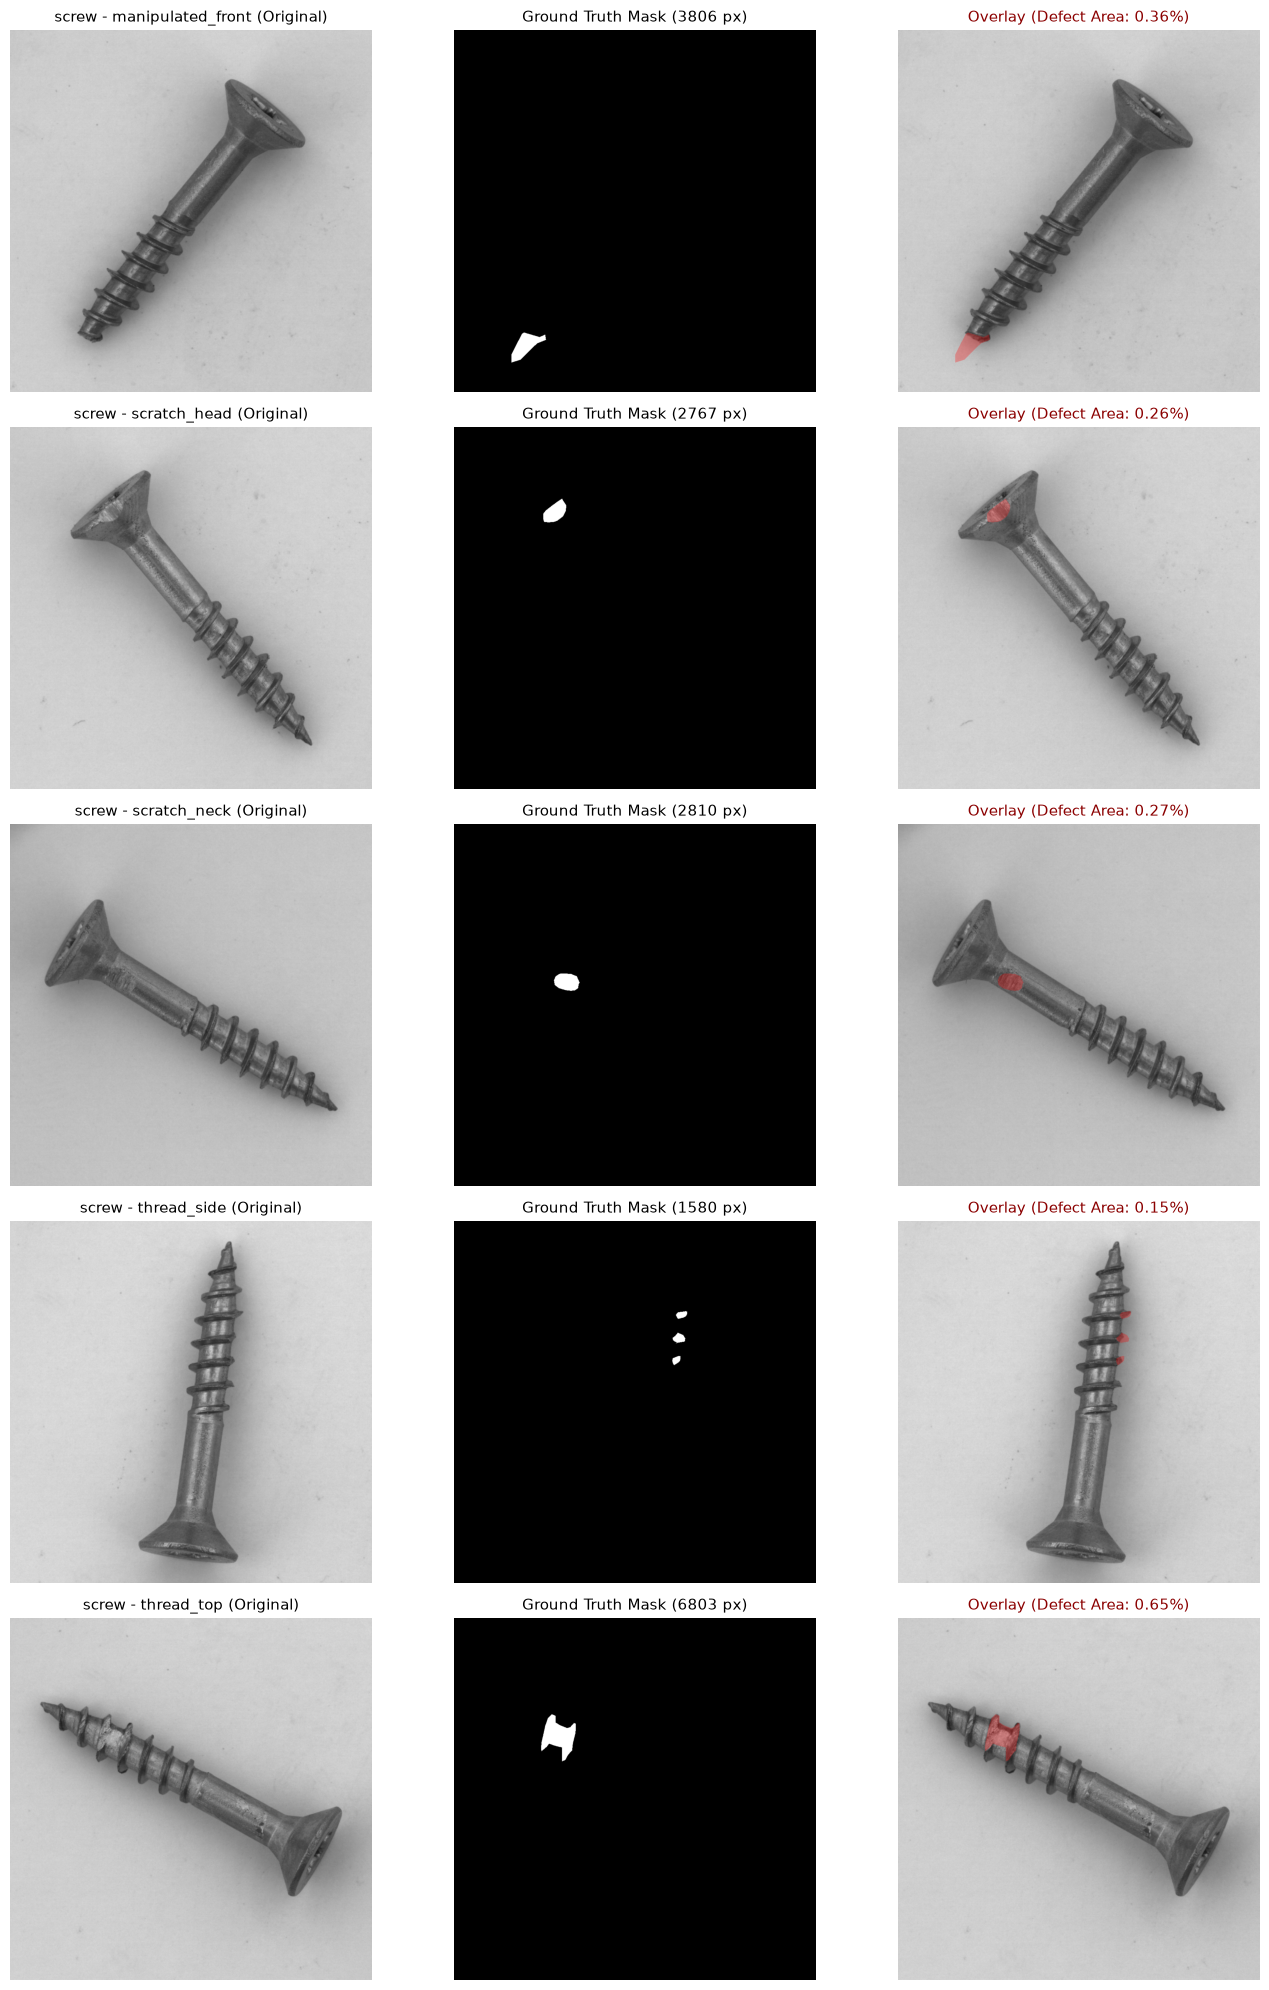


==================== [CAPSULE] DEFECT FOOTPRINT ====================
  • Defect: crack              | Defect Pixels:   2494 / 1000000 (0.249%)
  • Defect: faulty_imprint     | Defect Pixels:   2672 / 1000000 (0.267%)
  • Defect: poke               | Defect Pixels:  12289 / 1000000 (1.229%)
  • Defect: scratch            | Defect Pixels:   3260 / 1000000 (0.326%)
  • Defect: squeeze            | Defect Pixels:  76945 / 1000000 (7.694%)


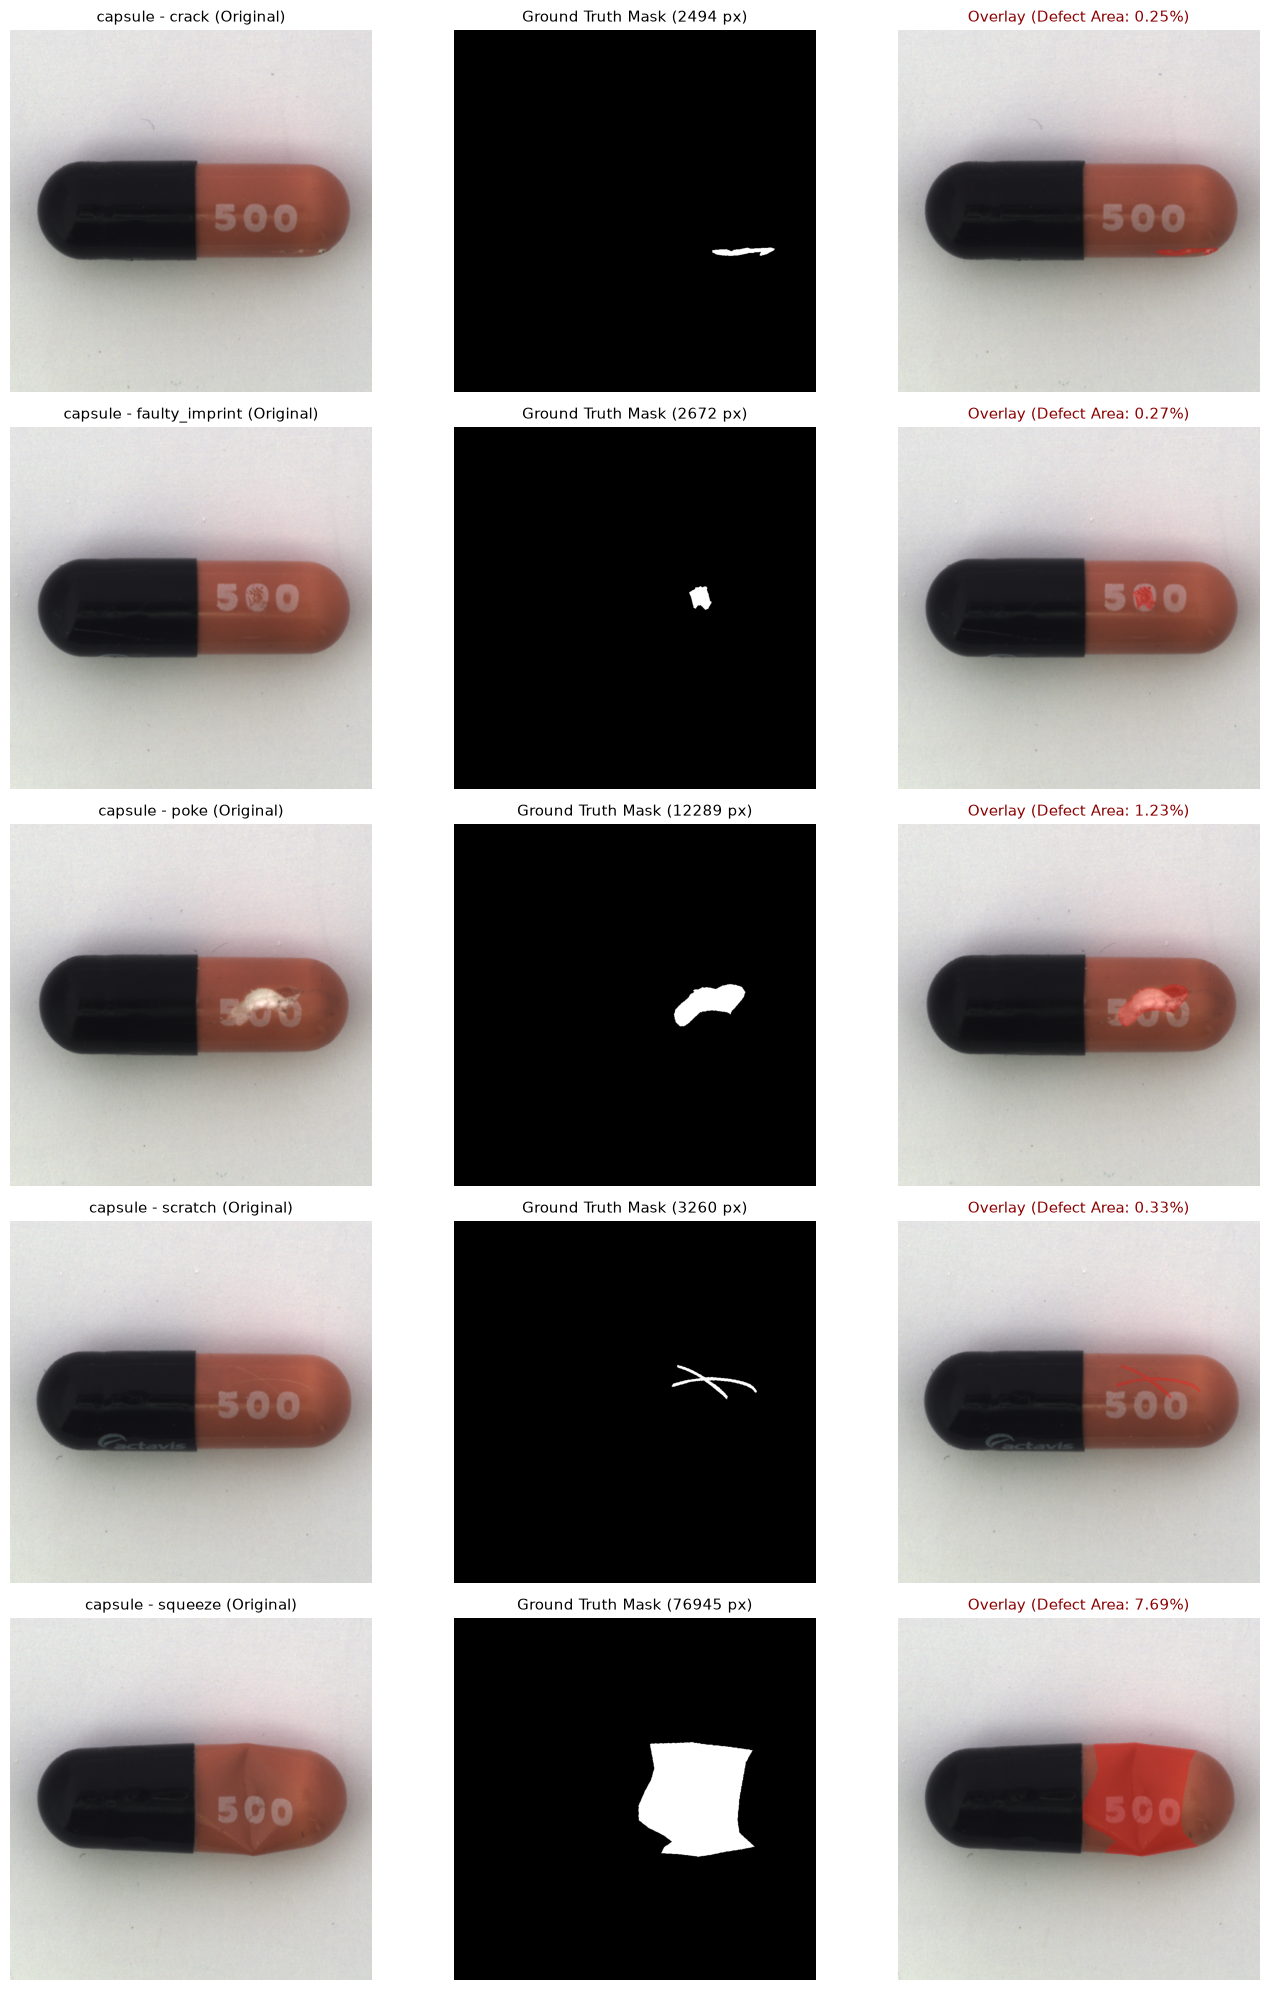

In [16]:
# Visualize defect footprints for screw and capsule
visualize_category_defects("screw")
visualize_category_defects("capsule")

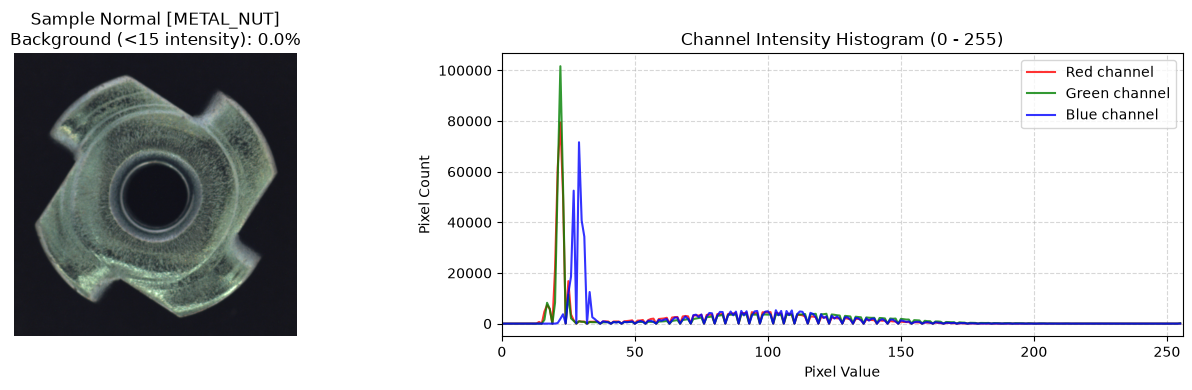

[METAL_NUT] Summary:
  • Mean RGB:  [57.2, 64.0, 63.6]
  • Std RGB:   [42.2, 49.0, 40.8]
  • Background: 0.00% of pixels are near-black (<15 intensity)



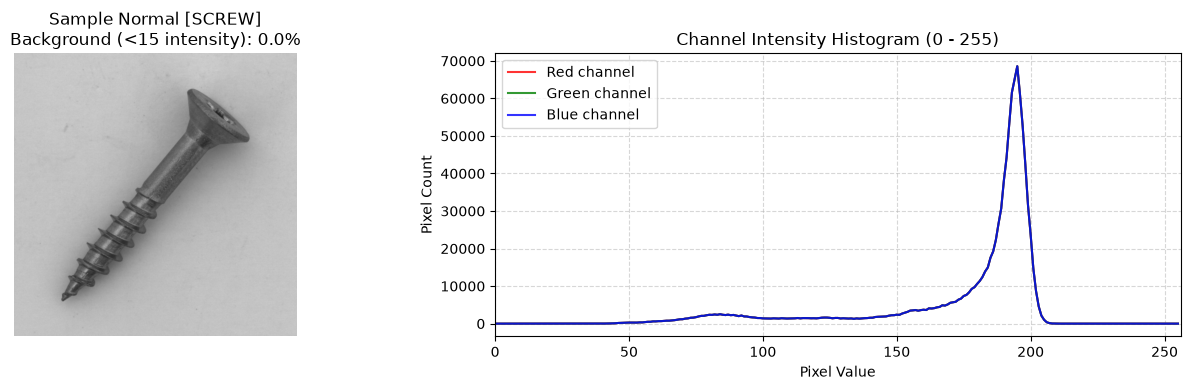

[SCREW] Summary:
  • Mean RGB:  [176.7, 176.7, 176.7]
  • Std RGB:   [32.8, 32.8, 32.8]
  • Background: 0.00% of pixels are near-black (<15 intensity)



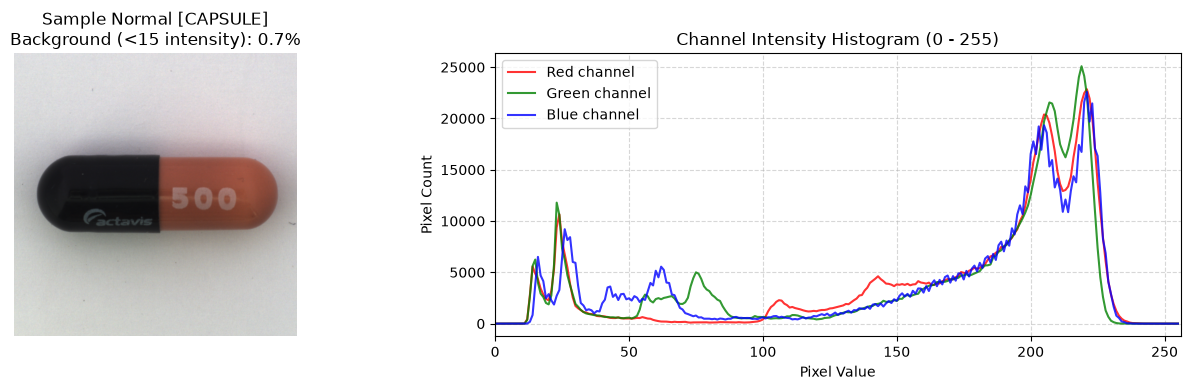

[CAPSULE] Summary:
  • Mean RGB:  [174.1, 167.0, 165.4]
  • Std RGB:   [59.4, 64.8, 66.6]
  • Background: 0.73% of pixels are near-black (<15 intensity)



In [17]:
def plot_intensity_distributions(category: str):
    """
    Analyzes the histogram of pixel intensities (0-255) across R, G, B channels
    to detect background dominance and value distribution.
    """
    normal_dir = raw_data_dir / category / "train" / "good"
    sample_normal_path = next(normal_dir.glob("*.png"))
    
    img = cv2.imread(str(sample_normal_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Calculate background ratio (pixels with intensity close to 0 across all channels)
    grayscale = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    background_pixels = np.count_nonzero(grayscale < 15)
    total_pixels = grayscale.size
    bg_ratio = (background_pixels / total_pixels) * 100
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Show normal image
    axes[0].imshow(img)
    axes[0].set_title(f"Sample Normal [{category.upper()}]\nBackground (<15 intensity): {bg_ratio:.1f}%")
    axes[0].axis("off")
    
    # Plot color channel histograms
    colors = ('red', 'green', 'blue')
    for i, color in enumerate(colors):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        axes[1].plot(hist, color=color, label=f"{color.capitalize()} channel", alpha=0.8)
        
    axes[1].set_title(f"Channel Intensity Histogram (0 - 255)")
    axes[1].set_xlabel("Pixel Value")
    axes[1].set_ylabel("Pixel Count")
    axes[1].set_xlim([0, 256])
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print(f"[{category.upper()}] Summary:")
    print(f"  • Mean RGB:  [{img[:,:,0].mean():.1f}, {img[:,:,1].mean():.1f}, {img[:,:,2].mean():.1f}]")
    print(f"  • Std RGB:   [{img[:,:,0].std():.1f}, {img[:,:,1].std():.1f}, {img[:,:,2].std():.1f}]")
    print(f"  • Background: {bg_ratio:.2f}% of pixels are near-black (<15 intensity)\n")

# Run distribution check across all three categories
for cat in target_categories:
    plot_intensity_distributions(cat)

## 5. Downscaling & Interpolation Benchmark (Hairline Defect Preservation)

[SCREW - scratch_head] Resizing from (1024, 1024) -> (256, 256)
  • Original mask unique values:  [  0 255]
  • Bilinear mask unique values:  [  0  64 128 191 255]  <-- Notice fuzzy non-binary artifacts!
  • Nearest mask unique values:   [  0 255] <-- Preserves strict binary (0, 255)



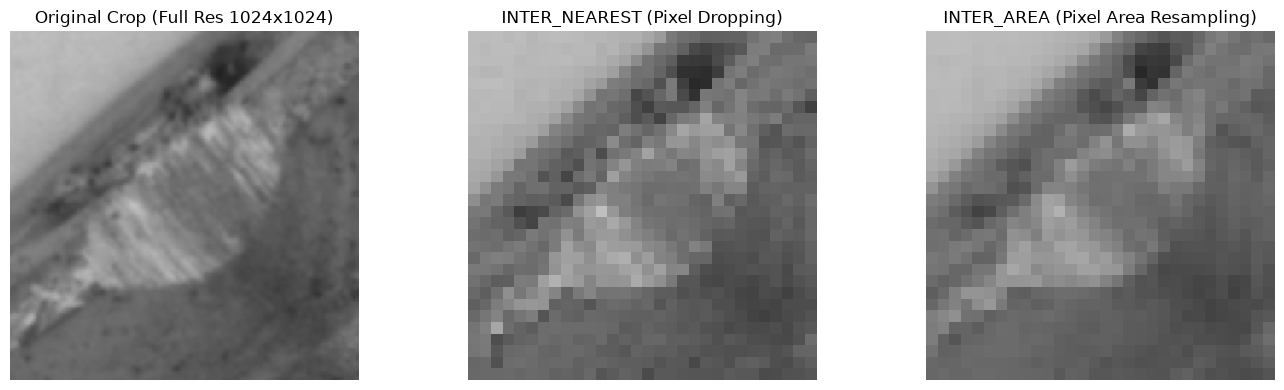

In [18]:
def benchmark_interpolation_methods(category: str = "screw", defect_type: str = "scratch_head"):
    """
    Compares how different interpolation algorithms preserve thin, high-frequency
    defects when downsampling from 1024x1024 to 256x256.
    """
    test_dir = raw_data_dir / category / "test" / defect_type
    sample_img_path = next(test_dir.glob("*.png"))
    sample_mask_path = raw_data_dir / category / "ground_truth" / defect_type / f"{sample_img_path.stem}_mask.png"
    
    # Load original full-resolution image and mask
    orig_img = cv2.imread(str(sample_img_path))
    orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    orig_mask = cv2.imread(str(sample_mask_path), cv2.IMREAD_GRAYSCALE)
    
    target_size = (256, 256)
    
    # Downsample using three different algorithms
    img_nearest = cv2.resize(orig_img, target_size, interpolation=cv2.INTER_NEAREST)
    img_linear  = cv2.resize(orig_img, target_size, interpolation=cv2.INTER_LINEAR)
    img_area    = cv2.resize(orig_img, target_size, interpolation=cv2.INTER_AREA)
    
    # Test mask resizing
    mask_linear = cv2.resize(orig_mask, target_size, interpolation=cv2.INTER_LINEAR)
    mask_nearest = cv2.resize(orig_mask, target_size, interpolation=cv2.INTER_NEAREST)
    
    print(f"[{category.upper()} - {defect_type}] Resizing from {orig_img.shape[:2]} -> {target_size}")
    print(f"  • Original mask unique values:  {np.unique(orig_mask)}")
    print(f"  • Bilinear mask unique values:  {np.unique(mask_linear)}  <-- Notice fuzzy non-binary artifacts!")
    print(f"  • Nearest mask unique values:   {np.unique(mask_nearest)} <-- Preserves strict binary {0, 255}\n")
    
    # Find bounding box around defect in original mask to zoom in
    y_indices, x_indices = np.where(orig_mask > 0)
    if len(y_indices) > 0:
        cy, cx = int(np.mean(y_indices)), int(np.mean(x_indices))
        # 120x120 crop around defect center in original
        half_crop = 60
        y1, y2 = max(0, cy - half_crop), min(orig_img.shape[0], cy + half_crop)
        x1, x2 = max(0, cx - half_crop), min(orig_img.shape[1], cx + half_crop)
        orig_crop = orig_img[y1:y2, x1:x2]
        
        # Proportional crop in 256x256 image (downscaled by factor of 4)
        scale_y = target_size[1] / orig_img.shape[0]
        scale_x = target_size[0] / orig_img.shape[1]
        cy_256, cx_256 = int(cy * scale_y), int(cx * scale_x)
        half_crop_256 = int(half_crop * scale_y)
        
        y1_s, y2_s = max(0, cy_256 - half_crop_256), min(256, cy_256 + half_crop_256)
        x1_s, x2_s = max(0, cx_256 - half_crop_256), min(256, cx_256 + half_crop_256)
        
        crop_nearest = img_nearest[y1_s:y2_s, x1_s:x2_s]
        crop_area = img_area[y1_s:y2_s, x1_s:x2_s]
        
        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        axes[0].imshow(orig_crop)
        axes[0].set_title(f"Original Crop (Full Res {orig_img.shape[0]}x{orig_img.shape[1]})")
        axes[0].axis("off")
        
        axes[1].imshow(crop_nearest)
        axes[1].set_title(f"INTER_NEAREST (Pixel Dropping)")
        axes[1].axis("off")
        
        axes[2].imshow(crop_area)
        axes[2].set_title(f"INTER_AREA (Pixel Area Resampling)")
        axes[2].axis("off")
        
        plt.tight_layout()
        plt.show()

# Run benchmark on screw with a scratch
benchmark_interpolation_methods("screw", "scratch_head")

## 6. Summary of Architectural Decisions for Preprocessing Pipeline

1. **Unified Shape:** All images will be resized to `(256, 256, 3)` using `cv2.INTER_AREA` to preserve thin defect lines.
2. **Channel Normalization:** Single-channel grayscale images (like `screw`) will be converted to 3-channel RGB.
3. **Mask Processing:** Binary masks will be resized using `cv2.INTER_NEAREST` and scaled to `{0.0, 1.0}` float32.
4. **Data Normalization:** Raw uint8 `[0, 255]` will be normalized to `[0.0, 1.0]` float32 for stable neural network gradient flow.
5. **Zero Data Leakage:** The training set will strictly use `train/good`. A 15% normal validation set will be carved exclusively from `train/good` for loss monitoring and threshold calibration. Official test sets will remain untouched until final evaluation.